In [1]:
import matplotlib.pyplot as plt
import numpy as np

from challenge.dataset import Dataset
from challenge.metrics import (
    avg_proposals_per_image,
    evaluate_miss_rate,
    evaluate_proposal_recall,
    evaluate_soft_proposal_recall,
)
from challenge.models import FeatureBuilder, FeatureConfig
from challenge.visuals import (
    add_yolo_boxes,
    plot_image_with_boxes,
    print_proposal_metrics,
)


In [2]:
seed = 42

rng = np.random.default_rng(seed)

cfg = FeatureConfig(
    min_area_rel=0.0001,  # permissive
    min_edge_density=0.0,  # irrelevant now
    use_mser=True,
    mser_min_area_rel=0.0008,  # best efficiency
    mser_max_area_rel=0.25,  # best recall
    dedup_iou_thresh=0.40,  # good trade-off
)

In [3]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")

In [4]:
## Create small dataset for illustration
idx = rng.integers(low=0, high=len(train_data), size=50)
tiny_data = [train_data[i] for i in idx]

In [5]:
model = FeatureBuilder(cfg)

In [9]:
bboxs = model.propose_boxes(tiny_data)
bboxs = model.assign_labels(tiny_data, bboxs)

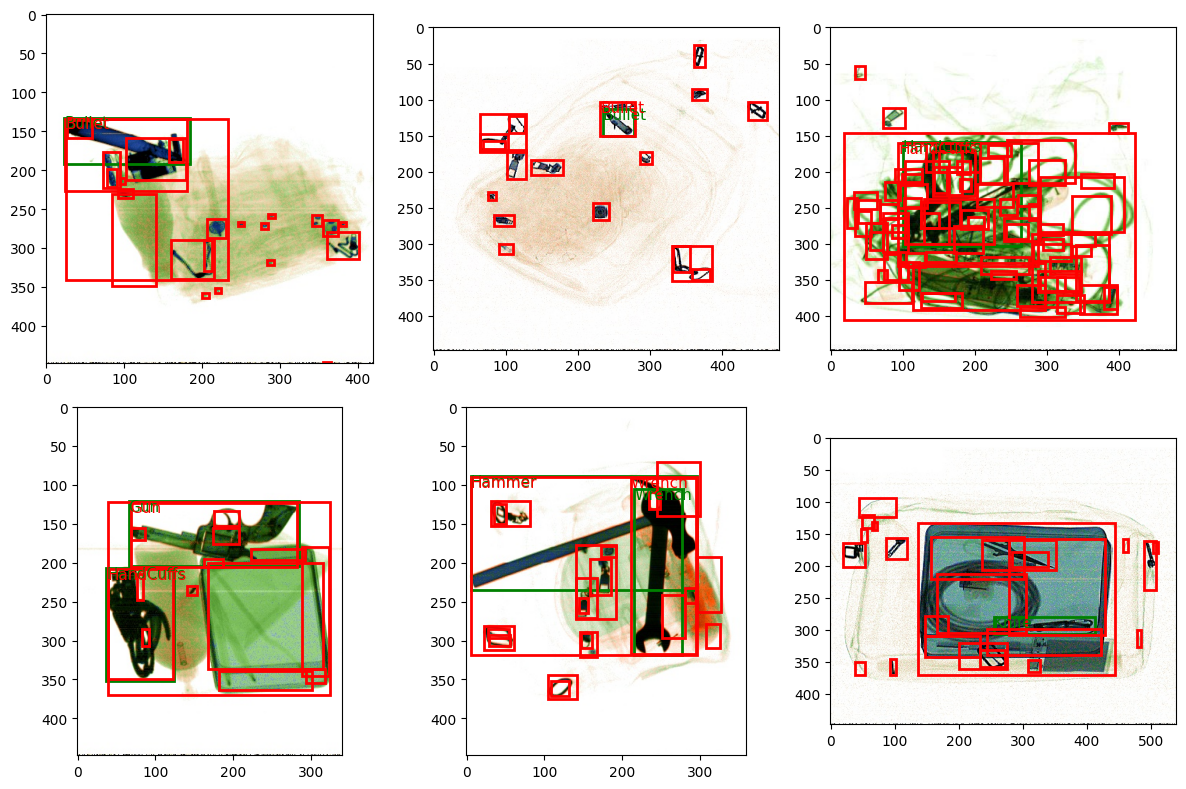

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()
for i, sample in enumerate(tiny_data[:6]):
    img = sample["image"]
    plot_image_with_boxes(
        ax[i],
        sample["image"],
        sample["targets"],
        color="green",
    )
    add_yolo_boxes(ax[i], bboxs[i], img.shape, color="red")

plt.tight_layout()


# Hyperparameter tuning

In [2]:
seed = 42
rng = np.random.default_rng(seed)

In [10]:
val_data = Dataset("../data/data_notebook.yaml", split="val")
idx = rng.integers(low=0, high=len(val_data), size=10)
tiny_data = [val_data[i] for i in idx]

In [11]:
cfg = FeatureConfig(min_area_rel=0.0001, min_edge_density=0, dedub_iou_thresh=0.45)
model = FeatureBuilder(cfg)

In [12]:
global_recall, _, recall_per_class, _ = evaluate_proposal_recall(
    model, tiny_data, iou_thresh=0.3, per_class=True
)
soft_recall = evaluate_soft_proposal_recall(model, tiny_data)
miss_rate = evaluate_miss_rate(model, tiny_data, iou_thresh=0.3)
avg_boxes = avg_proposals_per_image(model, tiny_data)

100%|██████████| 10/10 [00:00<00:00, 12.27it/s]


In [13]:
print_proposal_metrics(
    name="baseline",
    global_recall=global_recall,
    soft_recall=soft_recall,
    miss_rate=miss_rate,
    recall_per_class=recall_per_class,
    avg_boxes=avg_boxes,
)

 Proposal evaluation — baseline
Hard recall @ IoU=0.30 :  0.833
Soft recall (mean IoU) :  0.614
Miss rate @ IoU=0.30  :  0.167
Avg boxes / image     :   67.4
------------------------------------------------------------
Per-class recall:
  Class  0 :  0.667
  Class  1 :  1.000
  Class  2 :  1.000
  Class  3 :  1.000
  Class  4 :  1.000
  Class  5 :  0.500



In [19]:
from itertools import product

SWEEP_SPACE = {
    "dedub_iou_thresh": [0.40, 0.45, 0.50],
    "mser_min_area_rel": [0.0005, 0.0008, 0.001],
    "mser_max_area_rel": [0.15, 0.20, 0.25],
    "min_edge_density": [0.0, 0.003],
}


def run_proposal_sweep(base_cfg, loader, sweep_space):
    results = []

    keys = list(sweep_space.keys())
    values = list(sweep_space.values())

    for vals in product(*values):
        params = dict(zip(keys, vals))

        cfg = FeatureConfig(**{**base_cfg.__dict__, **params})
        model = FeatureBuilder(cfg)

        global_recall, _ = evaluate_proposal_recall(
            model, loader, iou_thresh=0.3, per_class=False
        )
        soft_recall = evaluate_soft_proposal_recall(model, loader)
        miss_rate = evaluate_miss_rate(model, loader, iou_thresh=0.3)
        avg_boxes = avg_proposals_per_image(model, loader)

        results.append(
            {
                **params,
                "hard_recall": global_recall,
                "soft_recall": soft_recall,
                "miss_rate": miss_rate,
                "avg_boxes": avg_boxes,
            }
        )

        print(
            f"[dedup={params['dedub_iou_thresh']:.2f} | "
            f"mser_min={params['mser_min_area_rel']:.4f} | "
            f"mser_max={params['mser_max_area_rel']:.2f} | "
            f"edge={params['min_edge_density']:.3f}] "
            f"=> hard={global_recall:.3f}, "
            f"soft={soft_recall:.3f}, "
            f"miss={miss_rate:.3f}, "
            f"boxes={avg_boxes:.1f}"
        )

    return results


In [21]:
base_cfg = FeatureConfig(min_area_rel=0.0001)

results = run_proposal_sweep(
    base_cfg=base_cfg,
    loader=val_data,
    sweep_space=SWEEP_SPACE,
)

100%|██████████| 900/900 [01:16<00:00, 11.76it/s]


[dedup=0.40 | mser_min=0.0005 | mser_max=0.15 | edge=0.000] => hard=0.755, soft=0.532, miss=0.245, boxes=49.3


100%|██████████| 900/900 [01:18<00:00, 11.40it/s]


[dedup=0.40 | mser_min=0.0005 | mser_max=0.15 | edge=0.003] => hard=0.755, soft=0.532, miss=0.245, boxes=49.3


100%|██████████| 900/900 [01:19<00:00, 11.27it/s]


[dedup=0.40 | mser_min=0.0005 | mser_max=0.20 | edge=0.000] => hard=0.765, soft=0.535, miss=0.235, boxes=49.5


... (42 outputs left out)

100%|██████████| 900/900 [01:05<00:00, 13.67it/s]


[dedup=0.45 | mser_min=0.0008 | mser_max=0.15 | edge=0.000] => hard=0.754, soft=0.539, miss=0.246, boxes=41.8


 24%|██▍       | 214/900 [00:15<00:50, 13.51it/s]


KeyboardInterrupt: 